In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("sentiment_analysis_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing Values:")
print(df.isnull().sum())

display(df.head(10))

Dataset Shape: (30, 2)

Columns: ['Review', 'Sentiment']

Missing Values:
Review       0
Sentiment    0
dtype: int64


,Review,Sentiment
0,This product is amazing and works perfectly,Positive
1,I absolutely love this purchase,Positive
2,Excellent quality and fast delivery,Positive
3,Very happy with the product,Positive
4,Great value for money,Positive
5,The quality is outstanding,Positive
6,Customer service was very helpful,Positive
7,I would definitely recommend this product,Positive
8,Fantastic experience overall,Positive
9,Works better than I expected,Positive


In [2]:
# Step 5: Text preprocessing

import re

# Create a copy of the dataset
df["Cleaned_Review"] = df["Review"].astype(str).str.lower()

# Remove punctuation and special characters
df["Cleaned_Review"] = df["Cleaned_Review"].apply(
    lambda text: re.sub(r"[^a-zA-Z\s]", "", text)
)

# Remove extra spaces
df["Cleaned_Review"] = df["Cleaned_Review"].str.strip()
df["Cleaned_Review"] = df["Cleaned_Review"].str.replace(
    r"\s+", " ", regex=True
)

print("Original and Cleaned Reviews:")
display(df[["Review", "Cleaned_Review", "Sentiment"]].head(10))

Original and Cleaned Reviews:


,Review,Cleaned_Review,Sentiment
0,This product is amazing and works perfectly,this product is amazing and works perfectly,Positive
1,I absolutely love this purchase,i absolutely love this purchase,Positive
2,Excellent quality and fast delivery,excellent quality and fast delivery,Positive
3,Very happy with the product,very happy with the product,Positive
4,Great value for money,great value for money,Positive
5,The quality is outstanding,the quality is outstanding,Positive
6,Customer service was very helpful,customer service was very helpful,Positive
7,I would definitely recommend this product,i would definitely recommend this product,Positive
8,Fantastic experience overall,fantastic experience overall,Positive
9,Works better than I expected,works better than i expected,Positive


Sentiment Counts:
Sentiment
Positive    10
Negative    10
Neutral     10
Name: count, dtype: int64


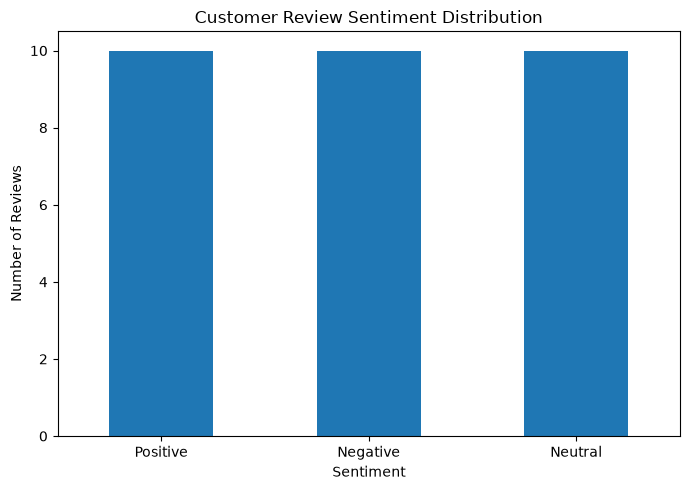

In [3]:
# Step 6: Sentiment distribution

import matplotlib.pyplot as plt

sentiment_counts = df["Sentiment"].value_counts()

print("Sentiment Counts:")
print(sentiment_counts)

# Create a bar chart
plt.figure(figsize=(7, 5))
sentiment_counts.plot(kind="bar")

plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("01_sentiment_distribution.png", dpi=300)
plt.show()

In [4]:
# Step 7: Sentiment percentage analysis

sentiment_counts = df["Sentiment"].value_counts()

sentiment_percentages = (
    df["Sentiment"].value_counts(normalize=True) * 100
).round(2)

summary = pd.DataFrame({
    "Review_Count": sentiment_counts,
    "Percentage": sentiment_percentages
})

print("Sentiment Analysis Summary:")
display(summary)

print("Total Reviews:", len(df))
print("Most Common Sentiment:", df["Sentiment"].mode()[0])

Sentiment Analysis Summary:


,Review_Count,Percentage
Sentiment,,
Positive,10,33.33
Negative,10,33.33
Neutral,10,33.33


Total Reviews: 30
Most Common Sentiment: Negative



Top words in Positive reviews:


,Word,Frequency
0,product,3
1,works,2
2,quality,2
3,amazing,1
4,perfectly,1
5,absolutely,1
6,love,1
7,purchase,1
8,excellent,1
9,fast,1


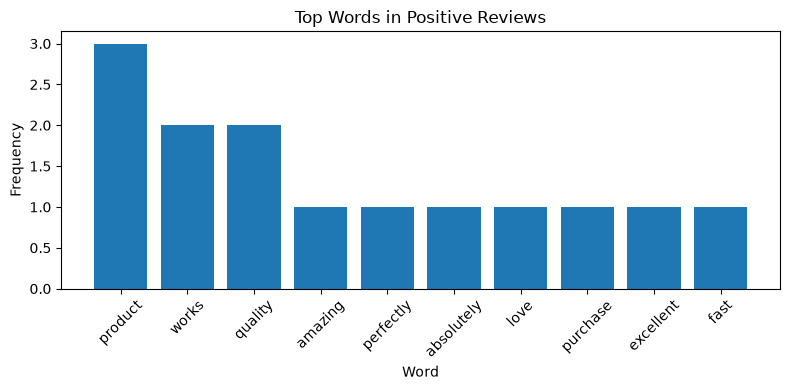


Top words in Negative reviews:


,Word,Frequency
0,product,4
1,quality,2
2,terrible,1
3,useless,1
4,am,1
5,disappointed,1
6,purchase,1
7,poor,1
8,bad,1
9,service,1


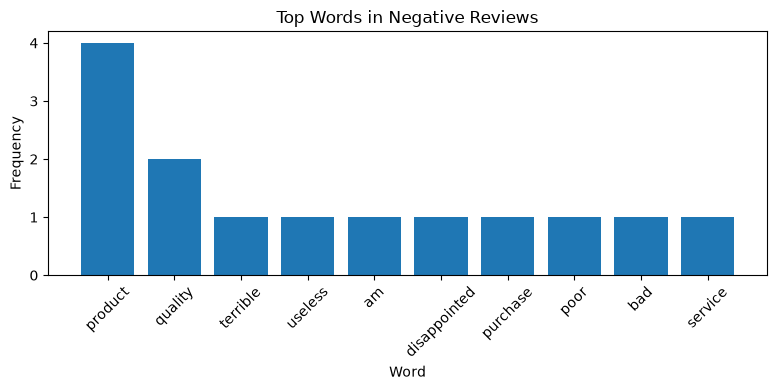


Top words in Neutral reviews:


,Word,Frequency
0,product,3
1,about,2
2,okay,1
3,delivery,1
4,neither,1
5,fast,1
6,nor,1
7,slow,1
8,works,1
9,as,1


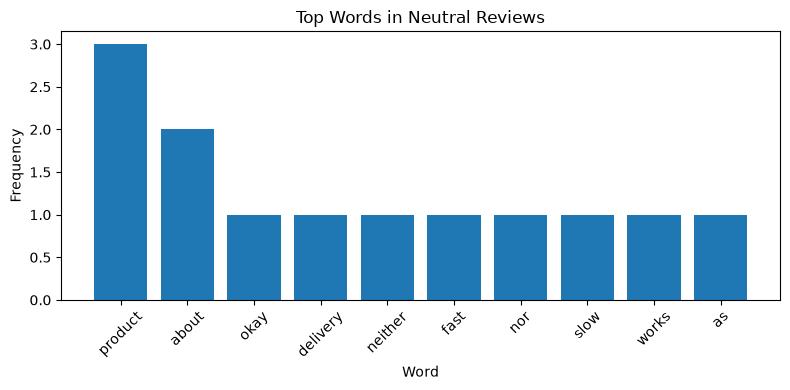

In [5]:
# Step 8: Word frequency analysis

from collections import Counter
import re
import matplotlib.pyplot as plt

# Common words that are less useful for sentiment analysis
stop_words = {
    "the", "is", "and", "a", "an", "i", "it", "this",
    "was", "for", "to", "of", "my", "with", "has",
    "have", "would", "than", "very", "some", "not"
}

# Count words separately for each sentiment
for sentiment in ["Positive", "Negative", "Neutral"]:
    text = " ".join(
        df.loc[df["Sentiment"] == sentiment, "Cleaned_Review"]
    )

    words = re.findall(r"\b[a-z]+\b", text)
    filtered_words = [word for word in words if word not in stop_words]

    word_counts = Counter(filtered_words)
    top_words = word_counts.most_common(10)

    print(f"\nTop words in {sentiment} reviews:")
    display(pd.DataFrame(top_words, columns=["Word", "Frequency"]))

    if top_words:
        words_df = pd.DataFrame(top_words, columns=["Word", "Frequency"])

        plt.figure(figsize=(8, 4))
        plt.bar(words_df["Word"], words_df["Frequency"])
        plt.title(f"Top Words in {sentiment} Reviews")
        plt.xlabel("Word")
        plt.ylabel("Frequency")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig(f"02_{sentiment.lower()}_word_frequency.png", dpi=300)
        plt.show()

In [6]:
# Step 9: Final analysis report

sentiment_counts = df["Sentiment"].value_counts()
sentiment_percentages = (
    df["Sentiment"].value_counts(normalize=True) * 100
).round(2)

print("FINAL SENTIMENT ANALYSIS REPORT")
print("=" * 35)

print("Total Reviews:", len(df))
print("Missing Reviews:", df["Review"].isnull().sum())

print("\nSentiment Summary:")
display(pd.DataFrame({
    "Review_Count": sentiment_counts,
    "Percentage": sentiment_percentages
}))

print("\nKEY FINDINGS")
print("1. The dataset contains 30 customer reviews.")
print("2. Positive, Negative, and Neutral each contain 10 reviews.")
print("3. Each sentiment represents approximately 33.33% of reviews.")
print("4. The word 'product' appears frequently across all categories.")
print("5. Negative reviews include words such as terrible, useless, poor, and disappointed.")
print("6. Positive reviews include words such as amazing, love, excellent, and fantastic.")

print("\nCONCLUSION")
print("The dataset has an equal distribution of positive, negative, and neutral reviews.")
print("Word frequency analysis highlights commonly used words in each sentiment category.")
print("These results describe this sample dataset and may not represent all customers.")

FINAL SENTIMENT ANALYSIS REPORT
Total Reviews: 30
Missing Reviews: 0

Sentiment Summary:


,Review_Count,Percentage
Sentiment,,
Positive,10,33.33
Negative,10,33.33
Neutral,10,33.33



KEY FINDINGS
1. The dataset contains 30 customer reviews.
2. Positive, Negative, and Neutral each contain 10 reviews.
3. Each sentiment represents approximately 33.33% of reviews.
4. The word 'product' appears frequently across all categories.
5. Negative reviews include words such as terrible, useless, poor, and disappointed.
6. Positive reviews include words such as amazing, love, excellent, and fantastic.

CONCLUSION
The dataset has an equal distribution of positive, negative, and neutral reviews.
Word frequency analysis highlights commonly used words in each sentiment category.
These results describe this sample dataset and may not represent all customers.
